In [2]:
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import genpareto, norm


In [3]:
def load_smallest_singular_values(path: str) -> np.ndarray:
    with h5py.File(path, "r") as h5f:
        sv = h5f["smallest_singular_value"][:]
    return sv.reshape(-1).astype(np.float64)


def load_smallest_distances(path: str, layer_name:str) -> np.ndarray:
    
    with h5py.File(path, "r") as h5f:
        
        print(h5f[layer_name].keys())
        id = h5f[layer_name]["input_distance"][:]
        od = h5f[layer_name]["output_distance"][:]
        
        
        
    return id.reshape(-1), od.reshape(-1)
    

def gpd_negloglik_hessian(shape: float, scale: float, exceedances: np.ndarray) -> np.ndarray:
    """Observed Fisher information (Hessian of the negative log-likelihood)
    of the GPD(shape, scale, loc=0) at the given parameters, evaluated on
    `exceedances`. Returns the (2, 2) Hessian in (xi, sigma) order.

    Analytic second derivatives of the GPD log-density
        l = -log(sigma) - (1 + 1/xi) * log(1 + xi*z/sigma)
    (obtained symbolically), summed over exceedances and negated. Using the
    closed form rather than finite differences avoids evaluating l outside
    its support {1 + xi*z/sigma > 0}, which happens easily near xi ~ -1
    where that support is a tight interval.
    """
    xi, sigma = shape, scale
    z = exceedances
    s = sigma + xi * z  # = sigma * (1 + xi*z/sigma), assumed > 0 (within GPD support)

    d_xixi = (xi**2 * z**2 * (xi + 1) + 2 * xi * z * s - 2 * s**2 * np.log(s / sigma)) / (
        xi**3 * s**2
    )
    d_sigmasigma = (sigma**2 - 2 * sigma * z - xi * z**2) / (sigma**2 * (s**2))
    d_xisigma = z * (s - z * (xi + 1)) / (sigma * s**2)

    hessian = -np.array(
        [
            [d_xixi.sum(), d_xisigma.sum()],
            [d_xisigma.sum(), d_sigmasigma.sum()],
        ]
    )
    return hessian



In [4]:

def fit_gpd_tail(
    g: np.ndarray,
    threshold: float | None,
    threshold_quantile: float | None,
    n_tail_min: int,
) -> dict:
    """Fits a GPD to the exceedances z = u - g[g < u] and, if the fitted
    shape is negative, estimates the finite lower endpoint c_hat = u +
    sigma/xi along with its confidence interval via the delta method."""
    g = np.sort(g)
    n = g.size

    if threshold is not None:
        u = threshold
    elif threshold_quantile is not None:
        u = np.quantile(g, threshold_quantile)
    else:
        # default: threshold s.t. at least n_tail_min points fall below it
        u = g[min(n_tail_min, n - 1)]
    # print(u)
    # print(g.min())
    # print(g.max())
    
    exceedances = u - g[g < u]
    print(exceedances)
    n_exc = exceedances.size
    if n_exc < 10:
        raise ValueError(
            f"only {n_exc} exceedances below threshold u={u:.6g} (need >= 10); "
            "lower threshold_quantile or raise threshold"
        )

    shape, _loc, scale = genpareto.fit(exceedances, floc=0)

    result = {
        "n_samples": int(n),
        "threshold": float(u),
        "n_exceedances": int(n_exc),
        "shape_xi": float(shape),
        "scale_sigma": float(scale),
        "g_min_observed": float(g[0]),
    }

    if shape < 0:
        # z = u - g has GPD(xi, sigma) support [0, -sigma/xi] for xi < 0
        # (sigma/xi < 0 here, so -sigma/xi > 0), i.e. g = u - z ranges over
        # [u - (-sigma/xi), u] = [u + sigma/xi, u]. The implied floor on g
        # is therefore the lower end of that range, u + sigma/xi -- NOT
        # u - sigma/xi (that would add a positive quantity to u, landing
        # above the threshold, outside the region any exceedance data
        # exists in).
        c_hat = u + scale / shape

        hessian = gpd_negloglik_hessian(shape, scale, exceedances)
        try:
            cov = np.linalg.inv(hessian)
        except np.linalg.LinAlgError:
            cov = np.full((2, 2), np.nan)

        # gradient of c_hat = u + sigma/xi w.r.t. (xi, sigma)
        grad = np.array([-scale / shape**2, 1.0 / shape])
        var_c_hat = float(grad @ cov @ grad)

        result["c_hat"] = float(c_hat)
        result["cov_xi_sigma"] = cov.tolist()
        result["var_c_hat"] = var_c_hat

        if var_c_hat > 0 and np.isfinite(var_c_hat):
            se_c_hat = float(np.sqrt(var_c_hat))
            result["se_c_hat"] = se_c_hat
            for level in (0.90, 0.95, 0.99):
                z = norm.ppf(level)
                result[f"lower_bound_{level:.2f}"] = c_hat - z * se_c_hat
        else:
            result["se_c_hat"] = None

        # Sanity checks specific to g being a smallest singular value
        # (always >= 0): the implied floor must be non-negative and at or
        # below every g value actually observed. Either violation means xi
        # is too close to 0 for sigma/xi to be a reliable extrapolation
        # (near-cancellation), so the estimate should not be trusted.
        if c_hat < 0 or c_hat > g[0] * 1.01:
            result["c_hat"] = None
            result["note"] = (
                f"shape xi={shape:.4g} < 0 but c_hat={c_hat:.6g} is outside the "
                f"valid range [0, observed min g={g[0]:.6g}]: fit is degenerate "
                "(xi too close to 0 for a reliable extrapolation) -- try a "
                "different threshold"
            )
    else:
        result["c_hat"] = None
        result["note"] = (
            f"shape xi={shape:.4g} >= 0: tail is unbounded below (or heavy-tailed) "
            "under the fitted GPD -- no finite infimum estimate"
        )

    return result


def plot_sigma_min(g: np.ndarray, layer_name: str, result: dict) -> None:
    """Two panels: (1) full histogram of sigma_min (g) with the fitted
    threshold u and, if available, the estimated infimum c_hat marked; (2)
    a zoomed view of the left tail (g < u) with the fitted GPD density
    overlaid on top of the exceedance histogram, so the fit can be checked
    visually against the data it was fit to."""
    u = result["threshold"]
    xi = result["shape_xi"]
    sigma = result["scale_sigma"]
    n_exc = result["n_exceedances"]

    fig, (ax_full, ax_tail) = plt.subplots(1, 2, figsize=(14, 5))

    ax_full.hist(g, bins=200, color="steelblue", alpha=0.8)
    ax_full.axvline(u, color="orange", linestyle="--", label=f"threshold u={u:.4g}")
    if result["c_hat"] is not None:
        ax_full.axvline(result["c_hat"], color="red", linestyle="--", label=f"c_hat={result['c_hat']:.4g}")
    ax_full.set_xlabel("sigma_min")
    ax_full.set_ylabel("count")
    ax_full.set_title(f"{layer_name}: full distribution (N={g.size})")
    ax_full.legend()

    # exceedances z = u - g for g < u, and the fitted GPD density on that
    # same z axis, transformed back to the g axis (g = u - z) for overlay.
    # Bin count is capped relative to n_exc so bins stay reasonably
    # populated (a handful of points per bin, rather than mostly-empty
    # bins) given the tail is usually a few hundred points at most.
    exceedances = u - g[g < u]
    n_bins = max(10, min(40, n_exc // 5))
    z_grid = np.linspace(0, exceedances.max(), 400)
    pdf_z = genpareto.pdf(z_grid, xi, loc=0, scale=sigma)
    g_grid = u - z_grid

    ax_tail.hist(
        g[g < u], bins=n_bins, color="steelblue", alpha=0.8, density=True, label="data (exceedances)"
    )
    ax_tail.plot(g_grid, pdf_z, color="black", linewidth=2, label=f"fitted GPD (xi={xi:.3g}, sigma={sigma:.3g})")
    if result["c_hat"] is not None:
        ax_tail.axvline(result["c_hat"], color="red", linestyle="--", label=f"c_hat={result['c_hat']:.4g}")
    ax_tail.set_xlabel("sigma_min")
    ax_tail.set_ylabel("density")
    ax_tail.set_title(f"{layer_name}: left-tail fit (n_exceedances={n_exc})")
    ax_tail.legend()

    fig.tight_layout()
    plt.show()


In [ ]:
# CONFIG
path = "/nfs-share/pa511/code_bases/new_jac/onnx_models/smoll/tangent_manifold_distances/add_6.add_8.h5"
# path = "/nfs-share/pa511/code_bases/new_jac/onnx_models/smoll/tangent_manifold_distances/add_102.add_104.h5"

# path = "onnx_models/smoll/tangent_manifold_distances/add_188.add_192.h5"
# path = "/nfs-share/pa511/code_bases/new_jac/onnx_models/smoll/tangent_manifold_distances/add_192.add_194.h5"
# path = "onnx_models/smoll/jacobian_stats/add_192.add_194.h5"
threshold = None  # exact threshold u; if set, overrides threshold_quantile and n_tail_min
threshold_quantile = 0.025  # quantile of g to use as threshold u
n_tail_min = 180  # used if threshold and threshold_quantile are both None

In [12]:
layer_name = os.path.splitext(os.path.basename(path))[0]
# print(load_smallest_distances(path, layer_name))
id, od= load_smallest_distances(path, layer_name)

<KeysViewHDF5 ['input_distance', 'k', 'output_distance', 'pos', 'sample_idx', 'vocab_id']>


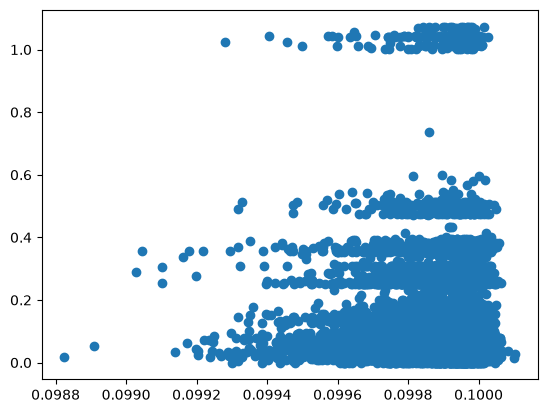

In [13]:
plt.scatter(id[:20000],od[:20000])

In [14]:
np.count_nonzero(od[:20000] == 0)

np.int64(148)

[1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.10592045e-01 1.10592045e-01 1.10592045e-01
 1.10592045e-01 1.105920

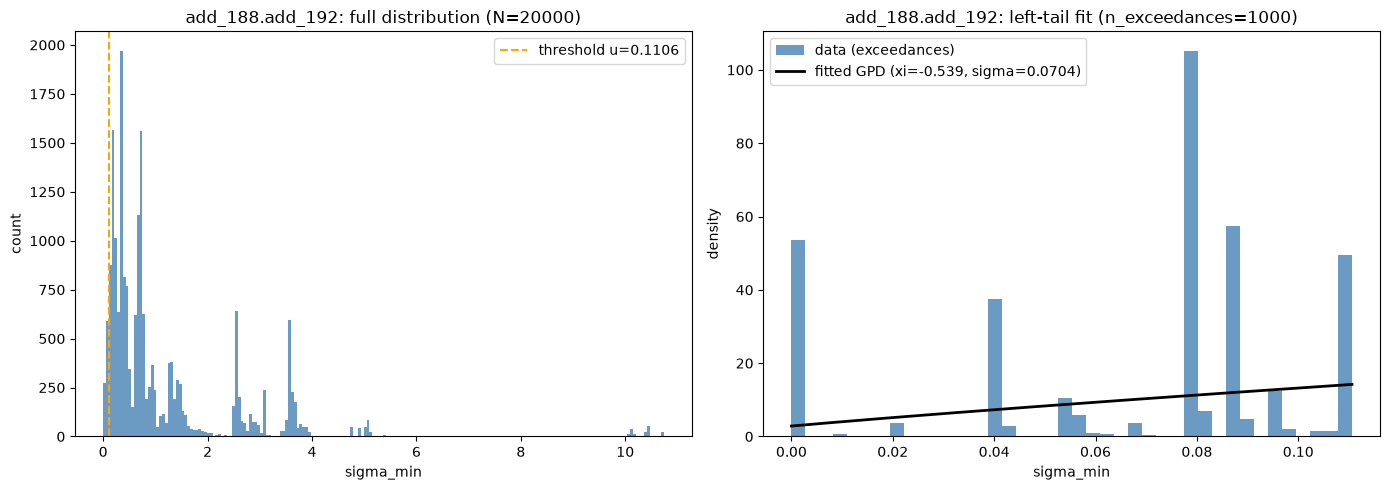

=== add_188.add_192 (onnx_models/smoll/tangent_manifold_distances/add_188.add_192.h5) ===
  N = 20000 samples, observed min g = 0
  threshold u = 0.110592 (1000 exceedances)
  fitted GPD: xi = -0.5388, sigma = 0.07035
  shape xi=-0.5388 < 0 but c_hat=-0.0199906 is outside the valid range [0, observed min g=0]: fit is degenerate (xi too close to 0 for a reliable extrapolation) -- try a different threshold


In [15]:
# path = "onnx_models/smoll/jacobian_stats/add_192.add_194.h5"
threshold = None  # exact threshold u; if set, overrides threshold_quantile and n_tail_min
threshold_quantile = 0.05  # quantile of g to use as threshold u
n_tail_min = None  # used if threshold and threshold_quantile are both None

g= od[:20000]/id[:20000]

result = fit_gpd_tail(
    g,
    threshold=threshold,
    threshold_quantile=threshold_quantile,
    n_tail_min=n_tail_min,
)

plot_sigma_min(g[:20000], layer_name, result)

print(f"=== {layer_name} ({path}) ===")
print(f"  N = {result['n_samples']} samples, observed min g = {result['g_min_observed']:.6g}")
print(
    f"  threshold u = {result['threshold']:.6g} "
    f"({result['n_exceedances']} exceedances)"
)
print(f"  fitted GPD: xi = {result['shape_xi']:.4g}, sigma = {result['scale_sigma']:.4g}")
if result["c_hat"] is not None:
    print(f"  c_hat (estimated inf g) = {result['c_hat']:.6g}")
    if result.get("se_c_hat") is not None:
        print(f"  se(c_hat) = {result['se_c_hat']:.4g}")
        for level in (0.90, 0.95, 0.99):
            lb = result[f"lower_bound_{level:.2f}"]
            print(f"  P(true inf >= {lb:.6g}) >= {level:.2f}")
    else:
        print("  se(c_hat) unavailable (singular Fisher information)")
else:
    print(f"  {result['note']}")


In [10]:
# # THRESHOLD SENSIaTIVITY SWEEP
# # Refits at a range of threshold_quantile values for the same `path`, so xi
# # and c_hat's stability (or lack of it) across thresholds is visible at a
# # glance -- a layer with a genuine finite floor should show xi consistently
# # < 0 and c_hat roughly stable over a range of quantiles, not just at one
# # lucky choice.
# sweep_quantiles = np.array([0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.04, 0.05, 0.075, 0.1])

# sweep_rows = []
# for q in sweep_quantiles:
#     try:
#         r = fit_gpd_tail(g, threshold=None, threshold_quantile=float(q), n_tail_min=n_tail_min)
#         sweep_rows.append(
#             {
#                 "quantile": q,
#                 "u": r["threshold"],
#                 "n_exc": r["n_exceedances"],
#                 "xi": r["shape_xi"],
#                 "c_hat": r["c_hat"],
#             }
#         )
#     except ValueError:
#         sweep_rows.append({"quantile": q, "u": np.nan, "n_exc": 0, "xi": np.nan, "c_hat": np.nan})

# print(f"{'quantile':>10} {'u':>12} {'n_exc':>7} {'xi':>10} {'c_hat':>12}")
# for row in sweep_rows:
#     c_hat_str = f"{row['c_hat']:.6g}" if row["c_hat"] is not None else "unreliable"
#     print(f"{row['quantile']:>10.4f} {row['u']:>12.6g} {row['n_exc']:>7} {row['xi']:>10.4g} {c_hat_str:>12}")

# fig, (ax_xi, ax_c) = plt.subplots(1, 2, figsize=(14, 4.5))

# xis = [row["xi"] for row in sweep_rows]
# ax_xi.plot(sweep_quantiles, xis, "o-", color="steelblue")
# ax_xi.axhline(0, color="gray", linestyle=":", linewidth=1)
# ax_xi.set_xlabel("threshold_quantile")
# ax_xi.set_ylabel("fitted xi")
# ax_xi.set_title(f"{layer_name}: shape xi vs. threshold")

# c_hats = [row["c_hat"] if row["c_hat"] is not None else np.nan for row in sweep_rows]
# ax_c.plot(sweep_quantiles, c_hats, "o-", color="darkred")
# ax_c.axhline(result["g_min_observed"], color="gray", linestyle=":", linewidth=1, label="observed min g")
# ax_c.set_xlabel("threshold_quantile")
# ax_c.set_ylabel("c_hat (NaN = unreliable fit)")
# ax_c.set_title(f"{layer_name}: c_hat vs. threshold")
# ax_c.legend()

# fig.tight_layout()
# plt.show()
